In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
# sklearn.set_config(display="text")

In [2]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)), #크기를 변경하는 것부터 시작 
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)), #크기를 변경하는 것부터 시작 
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

In [3]:
base_path = r"/Users/kdt_0900_lyn/ml/resoce/dataset"
train_path = os.path.join(base_path, "shape", "train")
test_path = os.path.join(base_path, "shape", "test")

In [4]:
train_dataset = ImageFolder(train_path, transform=train_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

print(len(train_dataset), len(test_dataset))

240 60


In [5]:

class_dict = dict(enumerate(train_dataset.classes))
class_dict

{0: 'cir', 1: 'tri', 2: 'x'}

## CNN 을 활용해서 도형 분류하기 실습 


In [6]:
# total_size = len(class_dict)       # 전체 이미지 개수 
# train_size = int(total_size * 0.8)   # 전체의 80%를 학습데이터 개수로 정함
# test_size = total_size - train_size

In [7]:
# print(train_size, test_size)

In [8]:
# train_subset, test_subset = random_split(class_dict, [train_size, test_size])

In [9]:
# train_transforms = transforms.Compose([
    
#     transforms.Resize((64, 64)),
#     # 컬러 RGB이미지를 채널1개의 흑백이미지로 변환 
#     transforms.Grayscale(1),
#     # 
#     transforms.ToTensor(),
#     transforms.Normalize(0.5, 0.5)
# ])

# test_transform = transforms.Compose([
#     transforms.Resize((64, 64)),
#     transforms.Grayscale(1),
#     transforms.ToTensor(),
#     transforms.Normalize(0.5, 0.5)
# ])

In [10]:
# class DatasetWrapper(Dataset):
#     def __init__(self, dataset, tranform=None):
#         self.dataset =dataset
#         self.tranform = tranform
#     def __len__(self):
#         return len(self.dataset)
#     def __getitem__(self, idx):
#         x, y = self.dataset[idx]
#         if self.tranform:
#             x = self.tranform(x)
#         return x, y

In [11]:
# train_dataset = DatasetWrapper(train_subset, tranform=train_transforms)
# test_dataset = DatasetWrapper(test_subset, tranform=test_transform)

In [12]:
# print(len(train_dataset), len(test_dataset))

In [13]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [28]:
imgs, labels = next(iter(train_dataloader))

In [29]:
print(imgs.size())

torch.Size([64, 1, 64, 64])


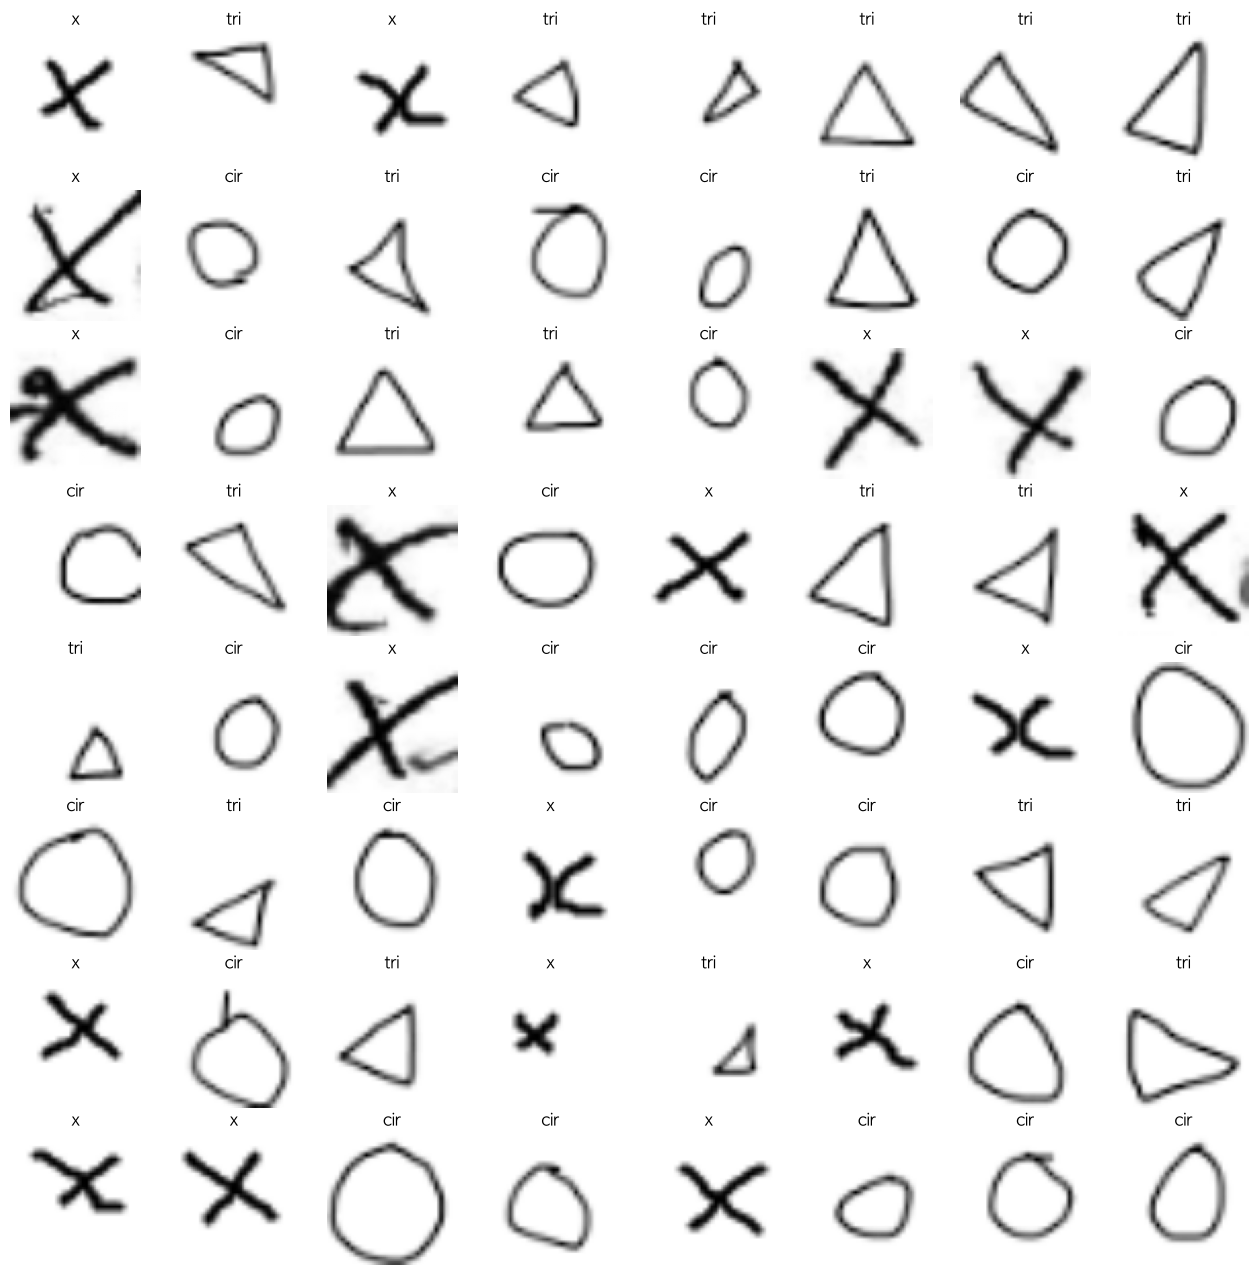

In [32]:
fig, axes = plt.subplots(8, 8, figsize=(16, 16)) 

for ax, img, label in zip(axes.flatten(), imgs, labels):
    ax.imshow(img.squeeze(0), cmap="gray")
    ax.set_title(class_dict.get(label.item(), 0))
    ax.axis("off")
plt.show()

In [33]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


In [34]:
# [CNN 모델]
class ConvNenuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25),   # 과적합 모델이 생길때 1.Dropout 없애기
            nn.Conv2d(28, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(56, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25)
        )
        self.linear = nn.Linear(56 * 16 * 16, 3)

    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        return x

In [35]:
model = ConvNenuralNetwork().to(device)

model
# linear : 출력층 

ConvNenuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Conv2d(1, 28, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): Conv2d(28, 28, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.25, inplace=False)
    (6): Conv2d(28, 56, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (7): ReLU()
    (8): Conv2d(56, 56, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.25, inplace=False)
  )
  (linear): Linear(in_features=14336, out_features=3, bias=True)
)

In [36]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)    

In [37]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        # 초기화
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss: {loss:.4f} | Accuracy: {batch_acc:.2f}")

    return running_loss / total, running_corrects / total

In [38]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            # 초기화
            outputs = model(imgs)
            loss = criterion(outputs, labels)
    
            batch_size = imgs.size(0)
            running_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            running_corrects += (preds == labels).sum().item()
            total += batch_size

    return running_loss / total, running_corrects / total

In [40]:
epochs = 10

for i in range(epochs):
    # 학습
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    # 평가
    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i + 1}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc * 100:.2f}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc * 100:.2f}")

Epoch: 1/10
[Train] Loss: 9.3845 | Accuracy: 1.25
[Test] Loss: 8.9568 | Accuracy: 0.00
Epoch: 2/10
[Train] Loss: 8.5618 | Accuracy: 0.42
[Test] Loss: 7.3144 | Accuracy: 0.00
Epoch: 3/10
[Train] Loss: 7.0006 | Accuracy: 0.42
[Test] Loss: 5.7099 | Accuracy: 0.00
Epoch: 4/10
[Train] Loss: 7.0973 | Accuracy: 0.42
[Test] Loss: 5.4642 | Accuracy: 15.00
Epoch: 5/10
[Train] Loss: 6.4168 | Accuracy: 3.33
[Test] Loss: 5.7851 | Accuracy: 33.33
Epoch: 6/10
[Train] Loss: 6.0567 | Accuracy: 8.75
[Test] Loss: 5.0118 | Accuracy: 31.67
Epoch: 7/10
[Train] Loss: 5.2634 | Accuracy: 7.50
[Test] Loss: 3.7274 | Accuracy: 31.67
Epoch: 8/10
[Train] Loss: 5.4896 | Accuracy: 7.50
[Test] Loss: 3.7641 | Accuracy: 31.67
Epoch: 9/10
[Train] Loss: 4.8061 | Accuracy: 13.75
[Test] Loss: 4.2174 | Accuracy: 33.33
Epoch: 10/10
[Train] Loss: 4.6715 | Accuracy: 21.25
[Test] Loss: 3.5084 | Accuracy: 33.33


In [52]:
img_path = r"/Users/kdt_0900_lyn/ml/resoce/drawing_copy.png"

shape = Image.open(img_path).convert("RGB")
input_tensor = test_transform(shape)
input_tensor_dev = input_tensor.to(device)

with torch.no_grad():
    outputs = model(input_tensor_dev)
    probs = F.softmax(outputs, dim=1)[0]

    pred_idx = torch.argmax(probs).item()
    pred_class = class_dict[pred_idx]
    confidence = probs[pred_idx].item() * 100

    print(f"예측결과: {pred_class}, 확률: {confidence:.2f}%")

예측결과: cir, 확률: 13.97%


## Grad-CAM(Gradient-weighted Class Activation Mapping)
- 딥러닝 인공지능(AI) 모델이 이미지를 보고 어떤 영역을 근거로 특정 클래스(결과)를 예측했는지 시각화해 주는 설명 가능한 AI(XAI, Explainable AI) 기법입니다

예측 결과: cir (확률: 5.8%, 클래스 번호: 0)


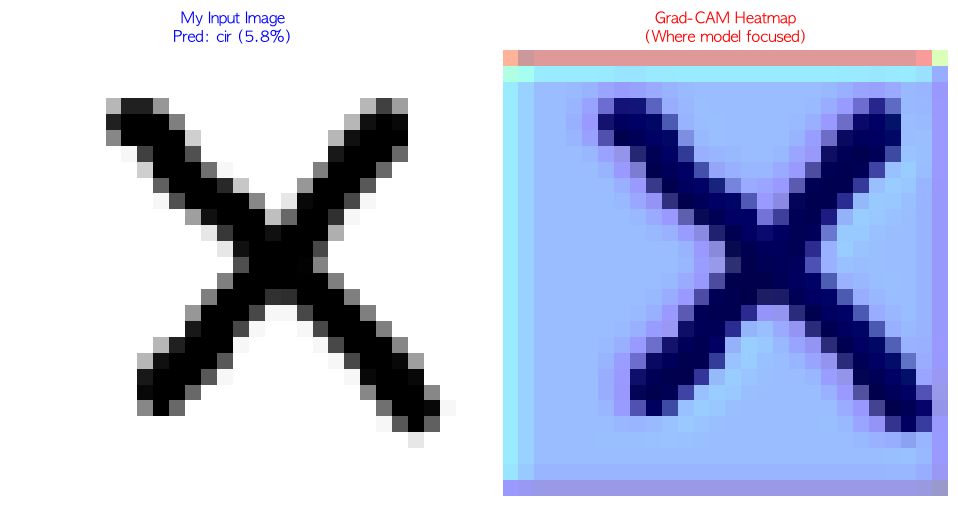

In [53]:
# 훅(Hook)을 사용하여 마지막 Convolution 층의 활성화 값과 그래디언트 추출 준비
activations = None
gradients = None

def forward_hook(module, input, output):
  global activations
  activations = output

def backward_hook(module, grad_input, grad_output):
  global gradients
  gradients = grad_output[0]


# 우리 모델의 classifier(또는 features) 안에서 마지막 Conv 레이어 지정
# 모델 구조에 맞게 마지막 Conv2d 레이어를 타겟으로 잡기
target_layer = model.classifier[-5]  # 마지막 직전 Conv2d 또는 마지막 Conv2d
target_layer.register_forward_hook(forward_hook)
target_layer.register_backward_hook(backward_hook)

# 테스트할 이미지 경로 설정 및 전처리 적용
original_image = Image.open(img_path).convert("RGB")

# test_transform 활용
input_tensor = test_transform(original_image).unsqueeze(0).to(
    device
)  # (C, H, W) -> (1, C, H, W)

# 순전파 및 추론
output = model(input_tensor)
probs = F.softmax(output, dim=1)[0]
pred_idx = torch.argmax(probs).item()
pred_class = class_dict[pred_idx]  # 클래스 이름 딕셔너리 (예: {0: 'circle', ...})
confidence = probs[pred_idx].item() * 100

print(f"예측 결과: {pred_class} (확률: {confidence:.1f}%, 클래스 번호: {pred_idx})")

# Grad-CAM 역전파 및 히트맵 계산
model.zero_grad()
class_score = output[0, pred_idx]
class_score.backward()

# 채널별 중요도 가중치 계산 (GAP 성향 반영)
pooled_gradients = torch.mean(gradients, dim=[0, 2, 3])
for i in range(activations.size(1)):
    activations[:, i, :, :] *= pooled_gradients[i]

heatmap = torch.mean(activations, dim=1).squeeze().cpu().detach().numpy()
heatmap = np.maximum(heatmap, 0)  # ReLU 적용 (양수 기여도만)
if heatmap.max() != 0:
    heatmap /= heatmap.max()  # 0~1 정규화

# PIL을 이용해 히트맵 크기를 원본 이미지 크기에 맞게 조절
heatmap_uint8 = np.uint8(255 * heatmap)
heatmap_pil = Image.fromarray(heatmap_uint8).resize(
    original_image.size, Image.Resampling.BILINEAR
)

# Matplotlib으로 원본 이미지와 Grad-CAM 오버레이 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 첫 번째: 원본 이미지 및 예측 결과
axes[0].imshow(original_image)
axes[0].set_title(f"My Input Image\nPred: {pred_class} ({confidence:.1f}%)", fontsize=11, color="blue",)
axes[0].axis("off")

# 두 번째: 원본 위에 히트맵 겹치기 (alpha=0.4로 반투명 효과)
axes[1].imshow(original_image)
axes[1].imshow(heatmap_pil, cmap="jet", alpha=0.4)  # jet 컬러맵으로 무지개빛 히트맵 표현
axes[1].set_title(f"Grad-CAM Heatmap\n(Where model focused)", fontsize=11, color="red")
axes[1].axis("off")

plt.tight_layout()
plt.show()